# Logistic Regression and Classification Error Metrics
![LogRegr.png](../assets/LogRegr.png)


# Obiectivele învățării

- Descrieți regresia logistică și modul în care aceasta diferă de regresia liniară
- Identificarea metricilor pentru erorile de clasificare și scenariile în care acestea pot fi utilizate


## Introducere

Vom utiliza baza de date [Human Activity Recognition with Smartphones] (https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), care a fost construită pe baza înregistrărilor participanților la studiu care efectuează activități de viață zilnică (ADL) în timp ce poartă un smartphone cu senzori inerțiali încorporați. Obiectivul este de a clasifica activitățile într-una dintre cele șase activități (mersul pe jos, mersul pe scări, mersul pe scări, șezutul, statul în picioare și întinderea) efectuate.

Pentru fiecare înregistrare din setul de date se furnizează: 

- accelerația triaxială de la accelerometru (accelerația totală) și accelerația corpului estimată. 
- Viteza triaxială unghiulară de la giroscop. 
- Un vector de 561 de caracteristici cu variabile în domeniul timpului și al frecvenței. 
- Eticheta activității sale. 

Mai multe informații despre caracteristici sunt disponibile pe site-ul de mai sus.

In [1]:
# Importuri pentru manipularea datelor si vizualizare
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calea catre date - compatibil indiferent de unde este rulat notebook-ul
data_path = ['..', 'data'] if os.path.exists(os.path.join('..', 'data')) else ['data']

# Incercam accelerarea Intel Scikit-learn daca este disponibila
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    pass

# Importuri din scikit-learn conform specificatiilor
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import precision_recall_fscore_support as score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize


Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Întrebarea 1

Importați datele și faceți următoarele:

* Examinați tipurile de date - există multe coloane, astfel încât ar putea fi înțelept să folosiți numărătoarea valorilor
* Determinați dacă valorile în virgulă flotantă trebuie să fie scalate
* Determinați defalcarea fiecărei activități
* Codificați eticheta activității ca un număr întreg

In [2]:
# Incarcam datele din setul Human Activity Recognition
filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
if not os.path.exists(filepath):
    filepath = 'Human_Activity_Recognition_Using_Smartphones_Data.csv'
data = pd.read_csv(filepath)

# Afisam dimensiunea setului de date si numaratoarea tipurilor de date
print("Dimensiunea setului de date (linii, coloane):", data.shape)
print("\nNumaratoarea tipurilor de date ale coloanelor:")
print(data.dtypes.value_counts())


Dimensiunea setului de date (linii, coloane): (10299, 562)

Numaratoarea tipurilor de date ale coloanelor:
float64    561
str          1
Name: count, dtype: int64


Coloanele de date sunt toate flotante, cu excepția etichetei de activitate.

In [3]:
# Verificam daca valorile in virgula flotanta trebuie scalate
float_cols = data.select_dtypes(include=['float64', 'float32']).columns

min_val = data[float_cols].min().min()
max_val = data[float_cols].max().max()

print(f"Valoarea minima pentru caracteristicile flotante: {min_val}")
print(f"Valoarea maxima pentru caracteristicile flotante: {max_val}")
print("Toate valorile sunt deja normalizate in intervalul [-1.0, 1.0], deci nu este necesara rescalarea.")


Valoarea minima pentru caracteristicile flotante: -1.0
Valoarea maxima pentru caracteristicile flotante: 1.0
Toate valorile sunt deja normalizate in intervalul [-1.0, 1.0], deci nu este necesara rescalarea.


Toate datele sunt scalate de la -1 (minim) la 1.0 (maxim).

In [4]:
# Determinam defalcarea fiecarei activitati (numar de aparitii si procente)
activity_counts = data['Activity'].value_counts()
activity_percentages = data['Activity'].value_counts(normalize=True) * 100

activity_breakdown = pd.DataFrame({
    'Numar instante': activity_counts,
    'Procent (%)': activity_percentages.round(2)
})

print("Defalcarea activitatilor in setul de date:")
print(activity_breakdown)


Defalcarea activitatilor in setul de date:
                    Numar instante  Procent (%)
Activity                                       
LAYING                        1944        18.88
STANDING                      1906        18.51
SITTING                       1777        17.25
WALKING                       1722        16.72
WALKING_UPSTAIRS              1544        14.99
WALKING_DOWNSTAIRS            1406        13.65


Examinați defalcarea activităților - acestea sunt relativ echilibrate.

Clasificatoarele Scikit learn nu vor accepta o matrice dispersată pentru coloana de predicție. Astfel, fie trebuie utilizat `LabelEncoder` pentru a converti etichetele de activitate în numere întregi, fie, dacă se utilizează `DictVectorizer`, matricea rezultată trebuie convertită într-o matrice non-sparse.  
Utilizați `LabelEncoder` pentru a fit_transforma coloana „Activity” și analizați 5 valori aleatorii.

In [5]:
# Codificam etichetele text ale activitatilor ca numere intregi folosind LabelEncoder
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])

print("Maparea claselor codificate:")
for idx, class_name in enumerate(le.classes_):
    print(f"  {idx} -> {class_name}")

print("\n5 valori aleatorii din coloana 'Activity' codificata:")
print(data['Activity'].sample(5, random_state=42))


Maparea claselor codificate:
  0 -> LAYING
  1 -> SITTING
  2 -> STANDING
  3 -> WALKING
  4 -> WALKING_DOWNSTAIRS
  5 -> WALKING_UPSTAIRS

5 valori aleatorii din coloana 'Activity' codificata:
5804    3
3688    0
7360    2
3437    2
8193    3
Name: Activity, dtype: int64


## Întrebarea 2

* Calculați corelațiile dintre variabilele dependente.
* Creați o histogramă a valorilor corelației
* Identificați cele care sunt cele mai corelate (fie pozitiv, fie negativ).

O histogramă a corelațiilor valorii absolute.

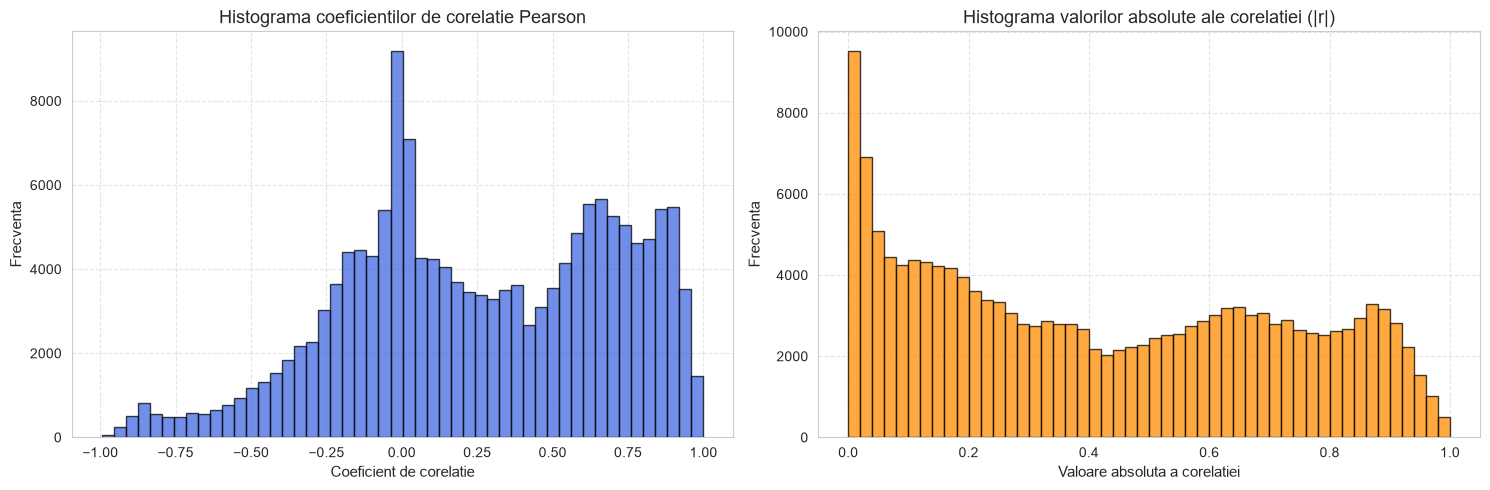

Top 5 perechi cu cea mai mare corelatie pozitiva:
           Caracteristica 1           Caracteristica 2  Corelatie
fBodyBodyGyroJerkMag-mean() fBodyBodyGyroJerkMag-sma()        1.0
    fBodyBodyGyroMag-mean()     fBodyBodyGyroMag-sma()        1.0
      tGravityAccMag-mean()       tGravityAccMag-sma()        1.0
     tBodyAccMag-arCoeff()4  tGravityAccMag-arCoeff()4        1.0
    tBodyGyroJerkMag-mean()     tBodyGyroJerkMag-sma()        1.0

Top 5 perechi cu cea mai puternica corelatie negativa:
         Caracteristica 1          Caracteristica 2  Corelatie
tGravityAcc-arCoeff()-Z,1 tGravityAcc-arCoeff()-Z,2  -0.995195
     tGravityAcc-mean()-Z      angle(Z,gravityMean)  -0.994764
tGravityAcc-arCoeff()-Z,2 tGravityAcc-arCoeff()-Z,3  -0.994628
tGravityAcc-arCoeff()-Z,3 tGravityAcc-arCoeff()-Z,4  -0.994267
     tGravityAcc-mean()-Y      angle(Y,gravityMean)  -0.993425

Top 5 perechi dupa valoarea absoluta a corelatiei:
       Caracteristica 1         Caracteristica 2  Corelatie  Corelat

In [6]:
# Selectam toate coloanele de caracteristici (excluzand eticheta tinta Activity)
feature_cols = [c for c in data.columns if c != 'Activity']

# Calculam matricea de corelatie a caracteristicilor
corr_matrix = data[feature_cols].corr()

# Extragem perechile unice din triunghiul superior fara diagonala principala
triu_indices = np.triu_indices_from(corr_matrix, k=1)
corr_values = corr_matrix.values[triu_indices]
abs_corr_values = np.abs(corr_values)

# Configurare stil grafice
sns.set_style('whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma valorilor de corelatie brute
axes[0].hist(corr_values, bins=50, color='royalblue', edgecolor='black', alpha=0.75)
axes[0].set_title('Histograma coeficientilor de corelatie Pearson', fontsize=13)
axes[0].set_xlabel('Coeficient de corelatie', fontsize=11)
axes[0].set_ylabel('Frecventa', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Histograma valorilor absolute ale corelatiilor
axes[1].hist(abs_corr_values, bins=50, color='darkorange', edgecolor='black', alpha=0.75)
axes[1].set_title('Histograma valorilor absolute ale corelatiei (|r|)', fontsize=13)
axes[1].set_xlabel('Valoare absoluta a corelatiei', fontsize=11)
axes[1].set_ylabel('Frecventa', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Construim un DataFrame pentru a identifica perechile cele mai corelate
pairs = []
for i, j in zip(triu_indices[0], triu_indices[1]):
    val = corr_matrix.values[i, j]
    pairs.append((feature_cols[i], feature_cols[j], val, abs(val)))

corr_df = pd.DataFrame(pairs, columns=['Caracteristica 1', 'Caracteristica 2', 'Corelatie', 'Corelatie_Absoluta'])

print("Top 5 perechi cu cea mai mare corelatie pozitiva:")
print(corr_df.sort_values(by='Corelatie', ascending=False).head(5)[['Caracteristica 1', 'Caracteristica 2', 'Corelatie']].to_string(index=False))

print("\nTop 5 perechi cu cea mai puternica corelatie negativa:")
print(corr_df.sort_values(by='Corelatie', ascending=True).head(5)[['Caracteristica 1', 'Caracteristica 2', 'Corelatie']].to_string(index=False))

print("\nTop 5 perechi dupa valoarea absoluta a corelatiei:")
print(corr_df.sort_values(by='Corelatie_Absoluta', ascending=False).head(5)[['Caracteristica 1', 'Caracteristica 2', 'Corelatie', 'Corelatie_Absoluta']].to_string(index=False))


## Întrebare 3

* Împărțiți datele în seturi de date de instruire și de testare. Acest lucru se poate face folosind orice metodă, dar luați în considerare utilizarea `StratifiedShuffleSplit` din Scikit-learn pentru a menține același raport al claselor de predictori.
* Indiferent de metodele utilizate pentru împărțirea datelor, comparați raportul claselor în ambele împărțiri, de formare și de testare.


In [7]:
# Impartim datele in seturi de instruire (70%) si testare (30%) folosind StratifiedShuffleSplit
strat_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

# Obtinem indecsii de train si test
train_idx, test_idx = next(strat_split.split(data[feature_cols], data['Activity']))

# Construim seturile de date
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'Activity']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'Activity']

# Comparam distributia claselor pentru a valida stratificarea
train_prop = y_train.value_counts(normalize=True).sort_index()
test_prop = y_test.value_counts(normalize=True).sort_index()
total_prop = data['Activity'].value_counts(normalize=True).sort_index()

class_balance_df = pd.DataFrame({
    'Activitate': [f"{i}: {le.classes_[i]}" for i in train_prop.index],
    'Train (%)': (train_prop.values * 100).round(2),
    'Test (%)': (test_prop.values * 100).round(2),
    'Total (%)': (total_prop.values * 100).round(2)
}).set_index('Activitate')

print("Comparatia distributiei claselor intre seturile de train si test:")
print(class_balance_df)
print(f"\nDimensiune X_train: {X_train.shape}, Dimensiune X_test: {X_test.shape}")


Comparatia distributiei claselor intre seturile de train si test:
                       Train (%)  Test (%)  Total (%)
Activitate                                           
0: LAYING                  18.88     18.87      18.88
1: SITTING                 17.26     17.25      17.25
2: STANDING                18.50     18.51      18.51
3: WALKING                 16.72     16.73      16.72
4: WALKING_DOWNSTAIRS      13.65     13.66      13.65
5: WALKING_UPSTAIRS        15.00     14.98      14.99

Dimensiune X_train: (7209, 561), Dimensiune X_test: (3090, 561)


## Întrebare 4

* Ajustați un model de regresie logistică fără regularizare folosind toate caracteristicile. Asigurați-vă că citiți documentația despre ajustarea unui model multiclasă, astfel încât să înțelegeți coeficientul de ieșire. Stocați modelul.
* Folosind validarea încrucișată pentru a determina hiperparametrii, ajustați modelele folosind regularizarea L1 și L2. De asemenea, stocați fiecare dintre aceste modele. Rețineți limitările privind modelele, soluțiile și regularizările multiclasă. Modelele regularizate, în special modelul L1, vor dura probabil ceva timp pentru a fi ajustate.

In [8]:
# 1. Model de regresie logistica fara regularizare (penalty=None)
# Folosim solverul 'lbfgs' care suporta nativ clasificarea multiclasa multinomiala
lr = LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

# 2. Model de regresie logistica cu regularizare L2 si validare incrucisata (4 fold-uri)
# Cautam cel mai bun C pe o grila logaritmica de 10 valori
lr_l2 = LogisticRegressionCV(Cs=10, cv=4, penalty='l2', solver='lbfgs', max_iter=1000, random_state=42, n_jobs=-1)
lr_l2.fit(X_train, y_train)

# 3. Model de regresie logistica cu regularizare L1 si validare incrucisata (4 fold-uri)
# Pentru regularizarea L1 in context multiclasa, utilizam solverul 'saga'
lr_l1 = LogisticRegressionCV(Cs=10, cv=4, penalty='l1', solver='saga', max_iter=500, tol=0.01, random_state=42, n_jobs=-1)
lr_l1.fit(X_train, y_train)

print("Antrenarea tuturor celor trei modele s-a incheiat cu succes!")
print(f"Hiperparametrul C optim pentru regularizarea L2: {lr_l2.C_[0]:.4f}")
print(f"Hiperparametrul C optim pentru regularizarea L1: {lr_l1.C_[0]:.4f}")


Antrenarea tuturor celor trei modele s-a incheiat cu succes!
Hiperparametrul C optim pentru regularizarea L2: 166.8101
Hiperparametrul C optim pentru regularizarea L1: 10000.0000


## Întrebarea 5

Comparați mărimile coeficienților pentru fiecare dintre modele. Dacă s-a utilizat ajustarea unu-vs-rest, fiecare set de coeficienți poate fi reprezentat separat. 

Pregătiți șase diagrame separate pentru fiecare dintre coeficienții multi-clasă.

Analiza selectiei de caracteristici (coeficienti egali cu zero):
  Model fara regularizare (lr): 0 din 3366 coeficienti nuli (0.00%)
  Model regularizat L2 (lr_l2): 0 din 3366 coeficienti nuli (0.00%)
  Model regularizat L1 (lr_l1): 0 din 3366 coeficienti nuli (0.00%)

Magnitudinea medie absoluta a coeficientilor (|coef|):
  Model fara regularizare (lr): 179.8245
  Model regularizat L2 (lr_l2): 0.4482
  Model regularizat L1 (lr_l1): 0.0914


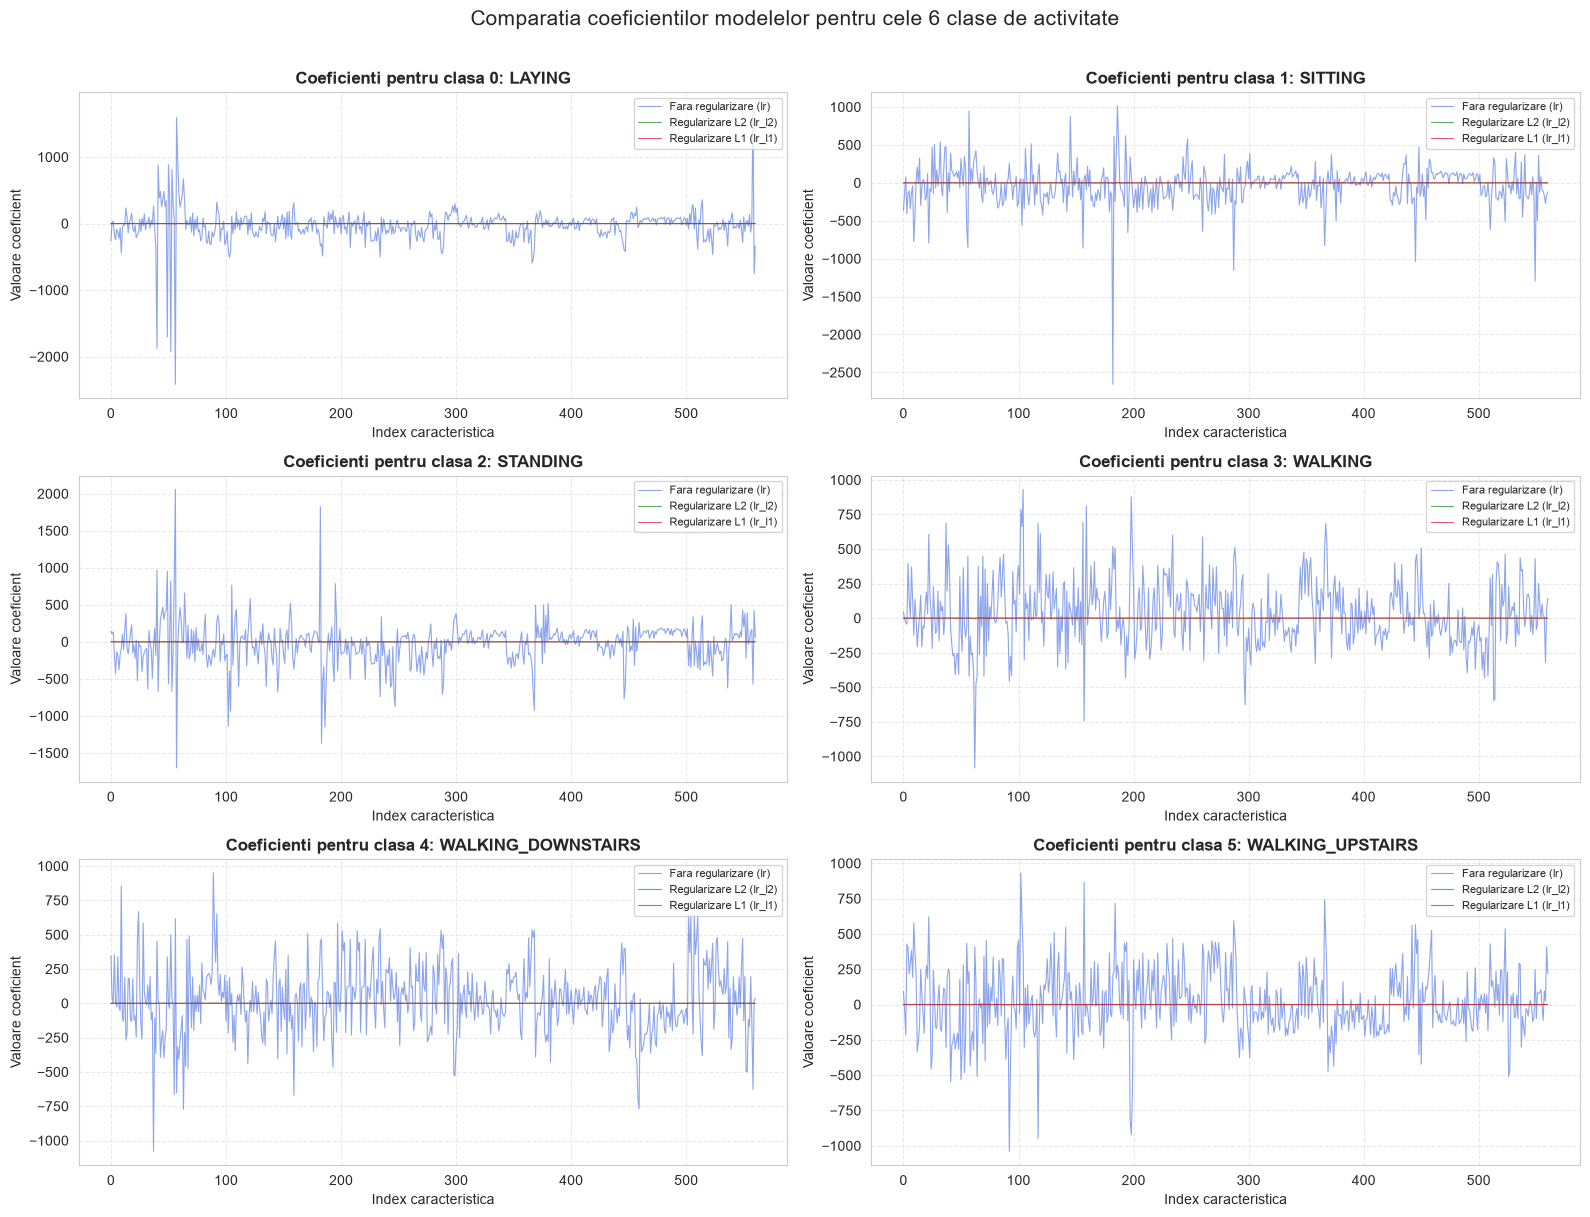

In [9]:
# Analizam numarul de coeficienti nuli (raritatea indusa de regularizare)
print("Analiza selectiei de caracteristici (coeficienti egali cu zero):")
print(f"  Model fara regularizare (lr): {np.sum(lr.coef_ == 0)} din {lr.coef_.size} coeficienti nuli ({np.mean(lr.coef_ == 0)*100:.2f}%)")
print(f"  Model regularizat L2 (lr_l2): {np.sum(lr_l2.coef_ == 0)} din {lr_l2.coef_.size} coeficienti nuli ({np.mean(lr_l2.coef_ == 0)*100:.2f}%)")
print(f"  Model regularizat L1 (lr_l1): {np.sum(lr_l1.coef_ == 0)} din {lr_l1.coef_.size} coeficienti nuli ({np.mean(lr_l1.coef_ == 0)*100:.2f}%)")

# Magnitudinea medie absoluta a coeficientilor
print("\nMagnitudinea medie absoluta a coeficientilor (|coef|):")
print(f"  Model fara regularizare (lr): {np.mean(np.abs(lr.coef_)):.4f}")
print(f"  Model regularizat L2 (lr_l2): {np.mean(np.abs(lr_l2.coef_)):.4f}")
print(f"  Model regularizat L1 (lr_l1): {np.mean(np.abs(lr_l1.coef_)):.4f}")

# Pregatim sase diagrame separate (grila 3 randuri x 2 coloane) pentru coeficientii fiecarei clase
fig, axList = plt.subplots(nrows=3, ncols=2, figsize=(16, 12))
axList = axList.flatten()

for i, ax in enumerate(axList):
    class_name = le.classes_[i]
    ax.plot(lr.coef_[i], label='Fara regularizare (lr)', color='royalblue', alpha=0.6, linewidth=0.8)
    ax.plot(lr_l2.coef_[i], label='Regularizare L2 (lr_l2)', color='forestgreen', alpha=0.7, linewidth=0.8)
    ax.plot(lr_l1.coef_[i], label='Regularizare L1 (lr_l1)', color='crimson', alpha=0.7, linewidth=0.8)
    
    ax.set_title(f'Coeficienti pentru clasa {i}: {class_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Index caracteristica', fontsize=10)
    ax.set_ylabel('Valoare coeficient', fontsize=10)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Comparatia coeficientilor modelelor pentru cele 6 clase de activitate', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()


## Întrebare 6

* Preziceți și stocați clasa pentru fiecare model.
* De asemenea, stocați probabilitatea pentru clasa prezisă pentru fiecare model. 

In [10]:
# Stocam modelele intr-un dictionar pentru iterare facila
models = {
    'lr': lr,
    'lr_l2': lr_l2,
    'lr_l1': lr_l1
}

# Dictionare pentru clasele prezise si probabilitati
y_pred = {}
y_prob = {}
y_prob_max = {}

for name, model in models.items():
    # Prezicem si stocam clasa pentru fiecare model
    y_pred[name] = model.predict(X_test)
    
    # Stocam distributia completa a probabilitatilor
    y_prob[name] = model.predict_proba(X_test)
    
    # Stocam probabilitatea asociata clasei prezise (probabilitatea maxima)
    y_prob_max[name] = y_prob[name].max(axis=1)

# Afisam predictiile si probabilitatile pentru primele 5 instante din setul de testare
preview_df = pd.DataFrame({
    'Eticheta Reala': [f"{v} ({le.classes_[v]})" for v in y_test.iloc[:5]],
    'Pred lr': y_pred['lr'][:5],
    'Prob lr': y_prob_max['lr'][:5].round(4),
    'Pred lr_l2': y_pred['lr_l2'][:5],
    'Prob lr_l2': y_prob_max['lr_l2'][:5].round(4),
    'Pred lr_l1': y_pred['lr_l1'][:5],
    'Prob lr_l1': y_prob_max['lr_l1'][:5].round(4)
})

print("Exemplu de predictii si probabilitati ale clasei prezise (primele 5 instante):")
print(preview_df)


Exemplu de predictii si probabilitati ale clasei prezise (primele 5 instante):
         Eticheta Reala  Pred lr  Prob lr  Pred lr_l2  Prob lr_l2  Pred lr_l1  \
0           3 (WALKING)        3      1.0           3         1.0           3   
1  5 (WALKING_UPSTAIRS)        5      1.0           5         1.0           5   
2           3 (WALKING)        3      1.0           3         1.0           3   
3           1 (SITTING)        1      1.0           1         1.0           1   
4            0 (LAYING)        0      1.0           0         1.0           0   

   Prob lr_l1  
0      0.9999  
1      0.9909  
2      0.9926  
3      0.9608  
4      0.9949  


## Întrebarea 7

Pentru fiecare model, calculați următoarele măsurători de eroare: 

* acuratețe
* precizie
* recall
* fscore
* matricea de confuzie

Decideți cum să combinați metricile multi-clasă într-o singură valoare pentru fiecare model.

In [11]:
# Binarizam etichetele reale de testare pentru calculul ROC-AUC multiclasa (One-vs-Rest)
y_test_bin = label_binarize(y_test, classes=range(len(le.classes_)))

metrics_list = []
cm_dict = {}

# Decizie de combinare a metricilor multiclasa:
# Utilizam media ponderata ('weighted') deoarece tine cont de numarul real de instante (suportul) al fiecarei clase,
# oferind o masura agregata robusta si echilibrata pe intreg setul de date de testare.

for name, model in models.items():
    # 1. Acuratete
    acc = accuracy_score(y_test, y_pred[name])
    
    # 2. Precizie, Recall si F-Score obtinute prin functia score (precision_recall_fscore_support)
    prec, rec, f1, _ = score(y_test, y_pred[name], average='weighted')
    
    # 3. ROC-AUC multiclasa (One-vs-Rest cu agregare ponderata)
    auc = roc_auc_score(y_test_bin, y_prob[name], average='weighted', multi_class='ovr')
    
    # 4. Matricea de confuzie
    cm = confusion_matrix(y_test, y_pred[name])
    cm_dict[name] = cm
    
    metrics_list.append({
        'Model': name,
        'Acuratete': acc,
        'Precizie (weighted)': prec,
        'Recall (weighted)': rec,
        'F1-Score (weighted)': f1,
        'ROC-AUC (weighted)': auc
    })

# Construim tabelul comparativ al metricilor
metrics_df = pd.DataFrame(metrics_list).set_index('Model')
print("Tabel recapitulativ al metricilor de clasificare:")
print(metrics_df.round(4))


Tabel recapitulativ al metricilor de clasificare:
       Acuratete  Precizie (weighted)  Recall (weighted)  F1-Score (weighted)  \
Model                                                                           
lr        0.9828               0.9828             0.9828               0.9828   
lr_l2     0.9851               0.9851             0.9851               0.9851   
lr_l1     0.9770               0.9772             0.9770               0.9770   

       ROC-AUC (weighted)  
Model                      
lr                 0.9960  
lr_l2              0.9994  
lr_l1              0.9991  


## Întrebarea 8

Afișați sau reprezentați grafic matricea de confuzie pentru fiecare model.

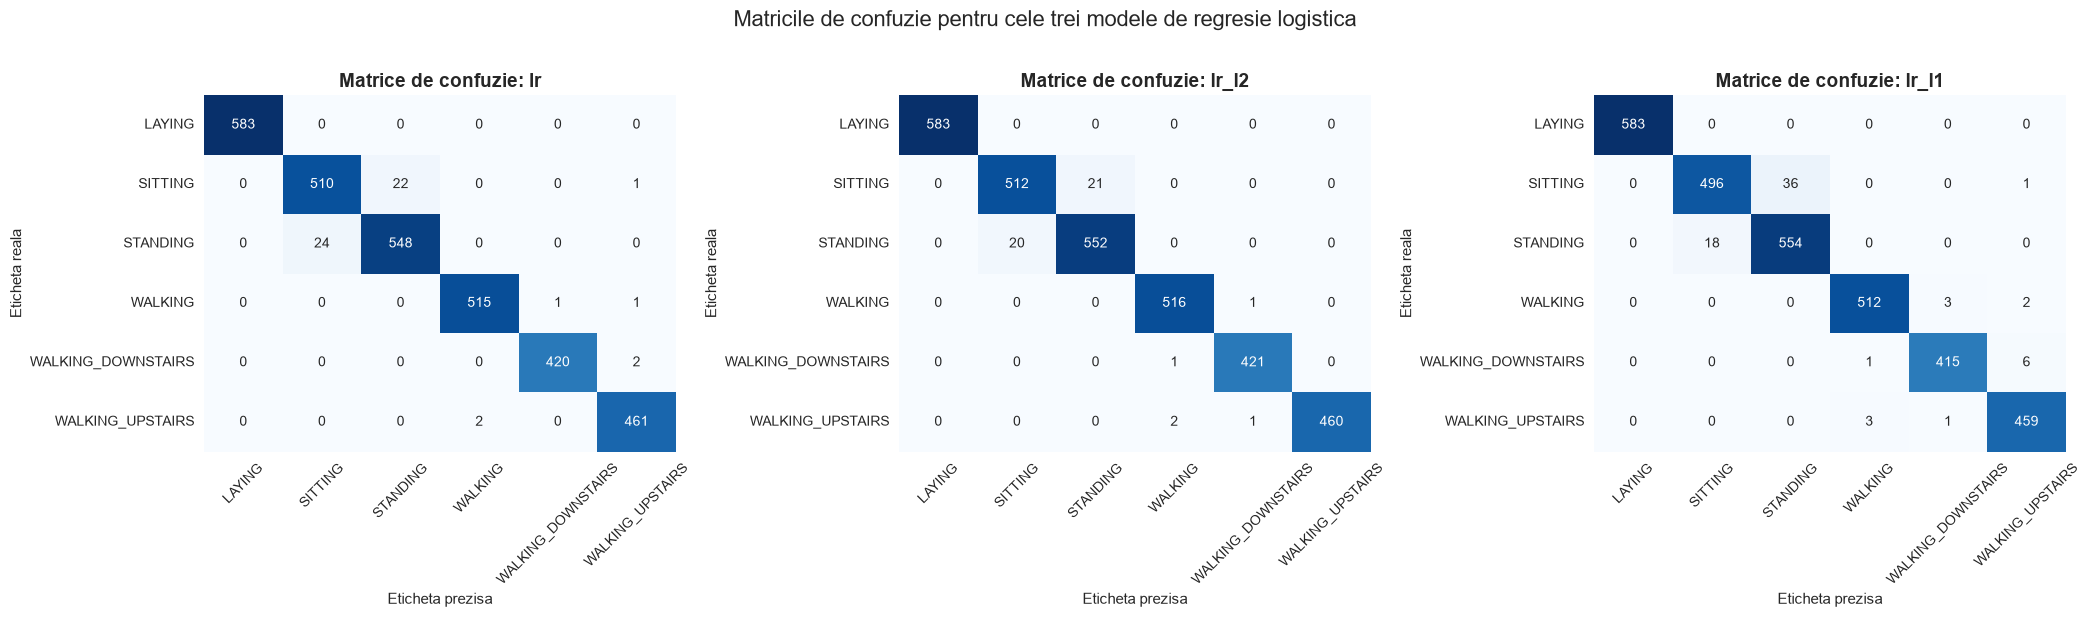

In [12]:
# Reprezentam grafic matricile de confuzie pentru fiecare model folosind heatmaps
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for idx, (name, cm) in enumerate(cm_dict.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[idx],
        cbar=False,
        xticklabels=le.classes_,
        yticklabels=le.classes_
    )
    axes[idx].set_title(f'Matrice de confuzie: {name}', fontsize=14, fontweight='bold')
    axes[idx].set_xlabel('Eticheta prezisa', fontsize=11)
    axes[idx].set_ylabel('Eticheta reala', fontsize=11)
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].tick_params(axis='y', rotation=0)

plt.suptitle('Matricile de confuzie pentru cele trei modele de regresie logistica', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()
